# Building LangGraph Agent with Persistent Memory

This tutorial builds a small Python Coding Assistant with an optional, durable `Memory.md` file. It uses:

- **DeepSeek V4.1 Flash** to write code and turn approved facts into compact Markdown memory.
- **Jev**, a System One decision model, to decide whether the current user message contains a durable preference or project fact.

## 1. Setup

Install the small set of packages once, then add `OPEN_ROUTER_KEY` to a `.env` file.

```bash
pip install langgraph langchain-openrouter langchain-typesafe python-dotenv ipython
```

In [2]:
import difflib
import html
import json
import os
import re
from pathlib import Path
from typing import Annotated, TypedDict

from dotenv import find_dotenv, load_dotenv
from IPython.display import HTML, Image, Markdown, display
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_openrouter import ChatOpenRouter
from langchain_typesafe import Noul, TypeSafeClassifier
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

import warnings
warnings.filterwarnings("ignore")

is_env_var_loaded = load_dotenv(find_dotenv())
print(f"Environment variables loaded: {'Yes' if is_env_var_loaded else 'No'}")

OPEN_ROUTER_KEY = os.environ.get("OPEN_ROUTER_KEY")

LLM_MODEL = "deepseek/deepseek-v4.1-flash"
JEV_URL = "https://openrouter.ai/api"

if OPEN_ROUTER_KEY:
    os.environ["TYPESAFE_API_KEY"] = OPEN_ROUTER_KEY

os.environ["TYPESAFE_BASE_URL"] = JEV_URL

Environment variables loaded: Yes


## 2. LLM + Jev

* **DeepSeek** is called through LangChain's `ChatOpenRouter` with typed message objects.
* **Jev** is called through LangChain's `TypeSafeClassifier`; it is not used to generate the memory itself. Its single `noul` question returns the probability that the current user message contains a durable fact worth remembering. We use a conservative threshold of `0.80`; tune it with a labeled sample for a real product. If Jev approves, the generative model rewrites the complete Markdown file under fixed headings.

In [3]:
deepseek_4_1_flash = ChatOpenRouter(
        model=LLM_MODEL,
        api_key=OPEN_ROUTER_KEY,
        temperature=0.0
)

jev_classifier = TypeSafeClassifier()

PREFERENCE_QUESTION = {
    "has_durable_preference": Noul(
        instructions="""
        Does `user_message` explicitly state a durable user preference, identity detail,
        technology preference, or active coding-project fact that would be useful in a
        future, separate conversation? Answer yes only for information worth retaining.
        Do not count a one-off question, a temporary task, a secret, or an assistant request.
        """,
    )
}


def preference_decision(user_message):
    """Ask one Jev noul question through LangChain and apply the write threshold."""
    response = jev_classifier.invoke(
        {
            "state": {"user_message": user_message},
            "questions": PREFERENCE_QUESTION,
        }
    )
    probability = float(response.nouls["has_durable_preference"].noul)
    return {"probability": probability, "should_update": probability >= 0.80}

In [15]:
example = preference_decision("I prefer Dask DataFrames for large CSV collections. Please write code using it.")

print(example)

{'probability': 0.89, 'should_update': True}


## 3. The human-readable `Memory.md` file

The file is small enough to inspect, edit, and delete. Memory updates replace incompatible values instead of accumulating them—if the user moves from PostgreSQL to Oracle, only Oracle should remain.

In [4]:
MEMORY_FILE = Path("Memory.md")
EMPTY_MEMORY = """# Coding Assistant Memory

## Personal
- No saved details yet.

## General Preferences
- No saved preferences yet.

## Technology Preferences
- No saved technology preferences yet.

## Projects
- No saved projects yet.
"""

def read_memory():
    if not MEMORY_FILE.exists():
        reset_memory()
    return MEMORY_FILE.read_text(encoding="utf-8")

def reset_memory():
    MEMORY_FILE.write_text(EMPTY_MEMORY, encoding="utf-8")
    
reset_memory()

In [14]:
print(read_memory())

# Coding Assistant Memory

## Personal
- No saved details yet.

## General Preferences
- No saved preferences yet.

## Technology Preferences
- Prefers polars for statistics.

## Projects
- No saved projects yet.



## 4. How to Update Contents of Memory.md File?

In [5]:
MEMORY_PROMPT = """You maintain a Markdown memory file for a Python Coding Assistant.

- Use only durable facts explicitly stated in the user message. 
- Keep the four exact headings, bullet-list style, and at most two meaningful bullets per section. 
- Each bullet must be 10 words or fewer, keyword-like, and useful in a future conversation. 
- Do not save secrets, guesses, one-off requests, or the assistant's ideas. 
- Merge related facts. 
- If a new fact conflicts with an old one in the same category, replace the old value — never retain both.

Current Memory.md:
---
{old_memory}
---

User message:
{user_message}

Return JSON only with keys `memory` (the complete updated Markdown file) and `reason`
(a short explanation)."""

def memory_decision(user_message, old_memory):
    """Return a complete, compact replacement file based only on user-provided facts."""
    messages = [
        SystemMessage(content="Return valid JSON only. Never use Markdown fences."),
        HumanMessage(content=MEMORY_PROMPT.format(old_memory=old_memory, user_message=user_message)),
    ]
    
    raw = deepseek_4_1_flash.invoke(messages, temperature=0.0).content
    
    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", raw.strip())
    
    try:
        result = json.loads(cleaned)
        if not isinstance(result["memory"], str):
            raise TypeError("memory must be a string")
        for heading in ("## Personal", "## General Preferences", "## Technology Preferences", "## Projects"):
            if heading not in result["memory"]:
                raise ValueError(f"Missing required heading: {heading}")
        return result
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        raise ValueError(f"Invalid memory-writer response: {raw}") from error

In [16]:
resp = memory_decision("When generating python code, please include types as well.", read_memory())

print(resp["reason"])
print(resp["memory"])

User requested type annotations for generated Python code, a durable general preference.
# Coding Assistant Memory

## Personal
- No saved details yet.

## General Preferences
- Prefers type hints in generated Python code.

## Technology Preferences
- Prefers polars for statistics.

## Projects
- No saved projects yet.


## 6. LangGraph Coding Agent

<img src="agent_workflow.png" width="420"/>

In [6]:
ASSISTANT_SYSTEM = """You are a concise Python Coding Assistant.
Generate correct, runnable Python when code is requested. Respect saved user preferences.
Do not claim to run code, access files, or use packages that you have not been given."""

class AgentState(TypedDict):
    # add_messages appends new messages and merges messages by ID when applicable.
    messages: Annotated[list[BaseMessage], add_messages]
    user_message: str
    memory: str
    reply: str
    preference_probability: float
    should_update_memory: bool
    memory_reason: str

def load_memory(state: AgentState):
    return {"memory": read_memory()}


def generate_code(state: AgentState):
    # The checkpointer restores earlier messages for this thread.
    # The current HumanMessage is already included in state["messages"].
    conversation = state.get("messages", [])
    messages = [
        SystemMessage(content=ASSISTANT_SYSTEM),
        SystemMessage(
            content="Saved Memory.md (User Preferences):\n" + state["memory"]
        ),
        *conversation,
    ]

    response = deepseek_4_1_flash.invoke(messages)

    return {
        "messages": [response],  # Save the assistant reply in the checkpointed history.
        "reply": response.content,
    }


def has_preference(state: AgentState):
    decision = preference_decision(state["user_message"]) ## Jev Call
    reason = f"Jev noul={decision['probability']:.2f}; threshold=0.80."
    return {
        "preference_probability": decision["probability"],
        "should_update_memory": decision["should_update"],
        "memory_reason": reason,
    }

def route_after_judge(state: AgentState):
    if state["should_update_memory"]:
        return "generate_memory_update"

    return END
    
def generate_memory_update(state: AgentState):        
    update = memory_decision(state["user_message"], state["memory"])
    return {
        "memory": update["memory"].strip() + "\n",
        "memory_reason": state["memory_reason"] + " ; LLM Reason:  " + update["reason"],
    }

def persist_memory(state: AgentState):
    MEMORY_FILE.write_text(state["memory"], encoding="utf-8")
    return {}

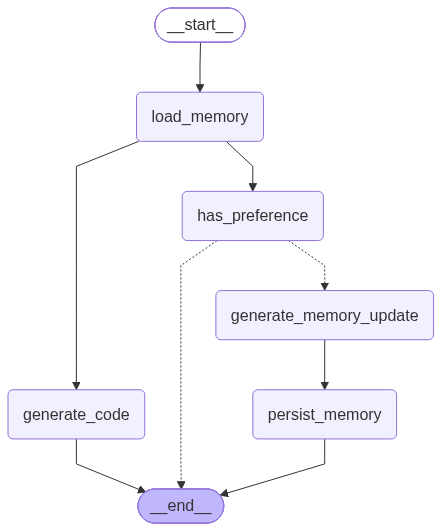

In [7]:
builder = StateGraph(AgentState)
builder.add_node("load_memory", load_memory)
builder.add_node("generate_code", generate_code)
builder.add_node("has_preference", has_preference)
builder.add_node("persist_memory", persist_memory)
builder.add_node("generate_memory_update", generate_memory_update)

builder.add_edge(START, "load_memory")

# These two independent nodes share the next LangGraph super-step.
builder.add_edge("load_memory", "generate_code")
builder.add_edge("load_memory", "has_preference")

# persist_memory is a join: it waits for both incoming branches.
builder.add_edge("generate_code", END)
builder.add_conditional_edges("has_preference", route_after_judge, {"generate_memory_update": "generate_memory_update", END: END})
builder.add_edge("generate_memory_update", "persist_memory")
builder.add_edge("persist_memory", END)

# InMemorySaver stores graph state separately for each thread_id.
checkpointer = InMemorySaver()
coding_graph = builder.compile(checkpointer=checkpointer)

# Render the graph inline. The Mermaid text fallback remains useful offline.
try:
    display(Image(coding_graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print(f"PNG graph rendering unavailable: {error}")
    print(coding_graph.get_graph().draw_mermaid())

In [8]:
class CodingAssistant:
    """A small wrapper that assigns a thread_id to each conversation."""
    def __init__(self, thread_id: str):
        self.thread_id = thread_id

    def ask(self, user_message: str):
        inputs = {
            "user_message": user_message,
            # add_messages appends this to the existing thread history.
            "messages": [HumanMessage(content=user_message)],
        }
        config = {
            "configurable": {
                "thread_id": self.thread_id,
            }
        }
        result = {}
        
        for update in coding_graph.stream(inputs, config=config, stream_mode="updates"):
            for node_update in update.values():
                if node_update:
                    result.update(node_update)
            
            if "generate_code" in update:
                reply = update["generate_code"]["reply"]
                display(Markdown(
                    f"### User\n\n{user_message}\n\n### Assistant\n\n{reply}"
                ))

        display(Markdown("------------"))
        display(Markdown(f"### Memory Update Reason?: {result["memory_reason"]}"))
        display(Markdown("------------"))
        return result

    def get_history(self):
        """Return the messages currently saved for this conversation thread."""
        state = coding_graph.get_state({
            "configurable": {"thread_id": self.thread_id}
        })
        return state.values.get("messages", [])

## 7. The difference: two conversation threads with shared long-term memory

### Conversation Thread 1

In [10]:
with_memory_thread_1 = CodingAssistant(thread_id="conversation_1")

_ = with_memory_thread_1.ask(
    "Write code to read sales.csv file and perform summary statistics on it."
)

### User

Write code to read sales.csv file and perform summary statistics on it.

### Assistant

Here's a script that reads `sales.csv` and prints a full set of summary statistics. It's defensive about missing files, empty data, and non-numeric columns.

```python
"""Read sales.csv and print summary statistics."""

from pathlib import Path
import sys

import pandas as pd


def load_sales(path: str = "sales.csv") -> pd.DataFrame:
    """Load the CSV, parsing date-like columns where it makes sense."""
    p = Path(path)
    if not p.is_file():
        sys.exit(f"Error: file not found -> {p.resolve()}")

    df = pd.read_csv(p)
    if df.empty:
        sys.exit(f"Error: {p} contains no data rows.")

    # Convert object columns that are mostly parseable dates into datetime.
    for col in df.select_dtypes(include="object").columns:
        parsed = pd.to_datetime(df[col], errors="coerce")
        if parsed.notna().mean() > 0.9:
            df[col] = parsed

    return df


def summarize(df: pd.DataFrame) -> None:
    print(f"Rows: {len(df):,}   Columns: {len(df.columns)}")

    print("\n--- Columns and dtypes ---")
    print(df.dtypes.to_string())

    print("\n--- Missing values ---")
    print(df.isna().sum().to_string())

    print("\n--- First 5 rows ---")
    print(df.head().to_string())

    # Numeric statistics
    numeric = df.select_dtypes(include="number")
    if numeric.empty:
        print("\nNo numeric columns found; skipping numeric statistics.")
    else:
        print("\n--- Numeric summary (describe) ---")
        print(numeric.describe().T.to_string())
        print("\n--- Column totals ---")
        print(numeric.sum().to_string())

    # Date ranges
    for col in df.select_dtypes(include="datetime").columns:
        print(f"\nDate range for '{col}': {df[col].min()} -> {df[col].max()}")

    # Low-cardinality categorical breakdowns
    for col in df.select_dtypes(include=["object", "category"]).columns:
        if df[col].nunique(dropna=False) <= 20:
            print(f"\n--- Value counts for '{col}' ---")
            print(df[col].value_counts(dropna=False).to_string())


if __name__ == "__main__":
    csv_path = sys.argv[1] if len(sys.argv) > 1 else "sales.csv"
    summarize(load_sales(csv_path))
```

Run it with:

```bash
python summarize_sales.py            # uses ./sales.csv
python summarize_sales.py other.csv  # or pass a path
```

Notes:
- Requires `pandas` (`pip install pandas`).
- The date-parsing step assumes any text column that's >90% parseable is a date; drop that loop if your data has text columns that look date-ish but aren't.
- If your file has a revenue/quantity column and you want per-region or per-month totals, add a group-by, e.g.:

```python
if {"region", "revenue"}.issubset(df.columns):
    print(df.groupby("region")["revenue"].agg(["count", "sum", "mean"]))
```

If you tell me the actual column names in your `sales.csv`, I can tailor the group-bys and drop the generic guessing.

------------

### Memory Update Reason?: Jev noul=0.07; threshold=0.80.

------------

In [11]:
_ = with_memory_thread_1.ask(
    "I prefer polars for statistics. Please rewrite the code using it."
)

### User

I prefer polars for statistics. Please rewrite the code using it.

### Assistant

Noted — switching to Polars. Here's the equivalent script:

```python
"""Read sales.csv and print summary statistics using Polars."""

from pathlib import Path
import sys

import polars as pl


def load_sales(path: str = "sales.csv") -> pl.DataFrame:
    """Load the CSV, letting Polars infer dtypes and parse ISO dates."""
    p = Path(path)
    if not p.is_file():
        sys.exit(f"Error: file not found -> {p.resolve()}")

    df = pl.read_csv(p, try_parse_dates=True)
    if df.height == 0:
        sys.exit(f"Error: {p} contains no data rows.")

    return df


def summarize(df: pl.DataFrame) -> None:
    print(f"Rows: {df.height:,}   Columns: {df.width}")

    print("\n--- Columns and dtypes ---")
    for name, dtype in df.schema.items():
        print(f"{name}: {dtype}")

    print("\n--- Missing values ---")
    print(
        df.null_count().transpose(
            include_header=True, header_name="column", column_names=["nulls"]
        )
    )

    print("\n--- First 5 rows ---")
    print(df.head(5))

    # Numeric statistics
    numeric = df.select(pl.selectors.numeric())
    if numeric.width == 0:
        print("\nNo numeric columns found; skipping numeric statistics.")
    else:
        print("\n--- Numeric summary (describe) ---")
        print(numeric.describe())
        print("\n--- Column totals ---")
        print(numeric.sum())

    # Date ranges
    for name, dtype in df.schema.items():
        if dtype in (pl.Date, pl.Datetime, pl.Time):
            print(f"\nDate range for '{name}': {df[name].min()} -> {df[name].max()}")

    # Low-cardinality categorical breakdowns
    for name, dtype in df.schema.items():
        if dtype in (pl.String, pl.Categorical, pl.Enum):
            if df[name].n_unique() <= 20:
                print(f"\n--- Value counts for '{name}' ---")
                print(df[name].value_counts(sort=True))


if __name__ == "__main__":
    csv_path = sys.argv[1] if len(sys.argv) > 1 else "sales.csv"
    summarize(load_sales(csv_path))
```

Run it with:

```bash
python summarize_sales.py            # uses ./sales.csv
python summarize_sales.py other.csv  # or pass a path
```

Notes:
- Requires `polars` (`pip install polars`).
- `try_parse_dates=True` handles ISO-style date columns automatically, so no manual date-guessing loop is needed.
- `pl.selectors.numeric()` picks up all numeric dtypes; swap in `pl.selectors.float()` or `pl.selectors.integer()` if you want to narrow it.
- On Polars < 0.20, `pl.String` is named `pl.Utf8` — change that one reference if you're on an older version.
- For per-group totals, add something like:

```python
if {"region", "revenue"}.issubset(df.columns):
    print(
        df.group_by("region")
        .agg(
            pl.len().alias("count"),
            pl.col("revenue").sum().alias("total"),
            pl.col("revenue").mean().alias("mean"),
        )
        .sort("total", descending=True)
    )
```

If you share the actual column names in your `sales.csv`, I can replace the generic detection with explicit group-bys and aggregations.

------------

### Memory Update Reason?: Jev noul=0.88; threshold=0.80. ; LLM Reason:  User stated a durable technology preference for polars in statistics.

------------

### Conversation Thread 2

In [12]:
with_memory_thread_2 = CodingAssistant(thread_id="conversation_2")

_ = with_memory_thread_2.ask(
    "Write code to analyze marketing.csv and generate summary statistics."
)

### User

Write code to analyze marketing.csv and generate summary statistics.

### Assistant

```python
import polars as pl

# Load the data
df = pl.read_csv("marketing.csv")

# Basic shape and schema
print(f"Rows: {df.height}, Columns: {df.width}")
print(df.schema)

# Summary statistics for all columns
print("\n--- Summary Statistics ---")
print(df.describe())

# Numeric column statistics
numeric_cols = [c for c, t in df.schema.items() if t.is_numeric()]
if numeric_cols:
    print("\n--- Numeric Summary ---")
    print(
        df.select(numeric_cols).describe()
    )

# Missing values per column
print("\n--- Missing Values ---")
print(
    df.null_count().transpose(include_header=True, header_name="column", column_names=["nulls"])
)

# Categorical / string column value counts
string_cols = [c for c, t in df.schema.items() if t == pl.Utf8]
for col in string_cols:
    print(f"\n--- Top values in '{col}' ---")
    print(
        df.group_by(col)
          .len()
          .sort("len", descending=True)
          .head(10)
    )

# Correlation matrix for numeric columns
if len(numeric_cols) > 1:
    print("\n--- Correlation Matrix ---")
    print(df.select(numeric_cols).corr())
```

Notes:
- Adjust the file path if `marketing.csv` lives elsewhere.
- If your CSV has a date column, parse it with `pl.read_csv("marketing.csv", try_parse_dates=True)` and add time-based aggregations (e.g., `group_by_dynamic`).
- For very large files, use `pl.scan_csv(...)` and `.collect()` after lazy operations.

------------

### Memory Update Reason?: Jev noul=0.07; threshold=0.80.

------------

## 8. Inspect updates, no-op requests, and replacements

These fresh requests exercise the long-term memory update policy. Notice that a one-off question should not alter the file, while an updated database preference should replace—not duplicate—the earlier database choice.

In [21]:
def show_memory_diff(before, after):
    """Show the highlighted unified diff."""
    lines = difflib.unified_diff(
        before.splitlines(), after.splitlines(),
        fromfile="Memory.md (before)", tofile="Memory.md (after)",
        lineterm="", n=10_000,
    )
    rendered = []
    for line in lines:
        css = "neutral"
        if line.startswith("+") and not line.startswith("+++"):
            css = "added"
        elif line.startswith("-") and not line.startswith("---"):
            css = "removed"
        elif line.startswith("@@"):
            css = "hunk"
        rendered.append(f'<span class="memory-diff-{css}">{html.escape(line) or "&nbsp;"}</span>')
    style = """<style>
    .memory-diff {border:1px solid #d0d7de;border-radius:6px;padding:12px;background:#f6f8fa;overflow-x:auto}
    .memory-diff span {display:block;font-family:var(--jp-code-font-family,monospace);white-space:pre}
    .memory-diff-added {background:#dafbe1;color:#116329}.memory-diff-removed {background:#ffebe9;color:#cf222e}
    .memory-diff-hunk {color:#0969da}.memory-diff-neutral {color:#57606a}
    </style>"""
    display(Markdown("#### What changed"))
    display(HTML(style + '<div class="memory-diff">' + "".join(rendered) + "</div>"))

show_memory_diff(
    "# Coding Assistant Memory\n\n## Personal\n- No saved details yet.\n\n## General Preferences\n- No saved preferences yet.\n\n## Technology Preferences\n- No saved technology preferences yet.\n\n## Projects\n- No saved projects yet.\n", 
    "# Coding Assistant Memory\n\n## Personal\n- Name: Sunny\n- Learning data engineering\n\n## General Preferences\n- No saved preferences yet.\n\n## Technology Preferences\n- Prefers polars for statistics.\n- Prefers Oracle Database for relational databases.\n\n## Projects\n- No saved projects yet.\n"
)

#### What changed

In [20]:
def ask_and_show_memory(agent, message):
    before = read_memory()
    result = agent.ask(message)
    after = read_memory()
    if before == after:
        display(Markdown("*No Memory.md change.*"))
    else:
        show_memory_diff(before, after)
    return result

### Personal Preference CASE

In [22]:
memory_demo = CodingAssistant(thread_id="memory_personal")

_ = ask_and_show_memory(memory_demo, "I am Sunny and I am learning data engineering.")

### User

I am Sunny and I am learning data engineering.

### Assistant

Nice to meet you, Sunny. Noted: you're learning data engineering, and you prefer **polars** for statistics work.

What would you like to tackle? A few things I can help with:

- **ETL/ELT pipelines** — reading, transforming, and writing data with polars
- **SQL** — query patterns, window functions, joins
- **Data modeling** — star schemas, normalization vs. denormalization
- **Orchestration** — Airflow DAGs, scheduling concepts
- **File formats** — Parquet, Avro, Delta Lake tradeoffs
- **Batch vs. streaming** — Spark, Kafka fundamentals

Tell me what you're working on (or paste code/errors) and I'll write runnable Python for it.

------------

### Memory Update Reason?: Jev noul=0.86; threshold=0.80. ; LLM Reason:  Added Sunny's name and data engineering learning to Personal; other sections unchanged.

------------

#### What changed

### Technology Preference CASE

In [23]:
memory_demo = CodingAssistant(thread_id="memory_technology_preference")

_ = ask_and_show_memory(memory_demo, "For relational databases, I prefer PostgreSQL.")

### User

For relational databases, I prefer PostgreSQL.

### Assistant

Noted — I've saved that preference:

**Technology Preferences**
- Prefers polars for statistics.
- Prefers PostgreSQL for relational databases.

I'll default to PostgreSQL in any SQL, schema, or database-connection examples unless you say otherwise. If you'd like, I can also note specifics like your usual driver (`psycopg` vs `asyncpg`), ORM (SQLAlchemy, Django ORM, none), or whether you use `polars.read_database` for pulling query results into a DataFrame.

------------

### Memory Update Reason?: Jev noul=0.96; threshold=0.80. ; LLM Reason:  Added durable technology preference for PostgreSQL relational databases.

------------

#### What changed

### NO Preference CASE

In [24]:
memory_demo = CodingAssistant(thread_id="memory_no_preference")

_ = ask_and_show_memory(memory_demo, "How do I list files in a directory with Python?")

### User

How do I list files in a directory with Python?

### Assistant

Use `pathlib` (modern, recommended) or `os`.

**pathlib — files only, non-recursive:**
```python
from pathlib import Path

for p in Path(".").iterdir():
    if p.is_file():
        print(p.name)
```

**pathlib — recursive:**
```python
from pathlib import Path

for p in Path(".").rglob("*"):
    if p.is_file():
        print(p)
```

**os — non-recursive:**
```python
import os

for name in os.listdir("."):
    if os.path.isfile(name):
        print(name)
```

**os.walk — recursive:**
```python
import os

for root, dirs, files in os.walk("."):
    for f in files:
        print(os.path.join(root, f))
```

**Glob patterns (e.g. only `.csv`):**
```python
from pathlib import Path

for p in Path(".").glob("*.csv"):
    print(p)
```

Notes:
- `iterdir()` / `listdir()` return entries in arbitrary order — sort with `sorted(...)` if needed.
- `rglob("*")` and `os.walk` recurse into subdirectories.
- `Path` objects give you `.name`, `.suffix`, `.stem`, `.parent`, and `.read_text()` for free.

------------

### Memory Update Reason?: Jev noul=0.03; threshold=0.80.

------------

*No Memory.md change.*

### Update Existing Preference CASE

In [25]:
memory_demo = CodingAssistant(thread_id="memory_update_existing_preference")

_ = ask_and_show_memory(memory_demo, "I will use Oracle Database instead of PostgreSQL going forward.")

### User

I will use Oracle Database instead of PostgreSQL going forward.

### Assistant

Got it — I'll use Oracle Database for relational work from here on instead of PostgreSQL.

A couple of notes so we're aligned:

- **Driver:** `python-oracledb` is the current official driver (it replaced `cx_Oracle`). Thin mode works with no Oracle Client install; thick mode is needed for some features.
- **Placeholders:** Oracle uses `:name` bind variables, not `%s` or `?`.
- **Polars:** still fine for the stats/DataFrame side — `pl.read_database()` / `write_database()` work with a SQLAlchemy engine or connection.

Example pattern I'll default to:

```python
import oracledb
import polars as pl

with oracledb.connect(user="scott", password="tiger", dsn="localhost/FREEPDB1") as conn:
    df = pl.read_database(
        "SELECT * FROM employees WHERE dept_id = :dept_id",
        connection=conn,
        execute_options={"parameters": {"dept_id": 10}},
    )
```

One thing I can't do: I don't have the ability to write to your saved memory file myself. If you want this to persist across sessions, you'll need to update the "Technology Preferences" section of your memory file to replace PostgreSQL with Oracle Database.

Want me to draft that updated memory snippet for you?

------------

### Memory Update Reason?: Jev noul=0.94; threshold=0.80. ; LLM Reason:  Replaced PostgreSQL preference with Oracle per user's stated change.

------------

#### What changed

## Why this split works

| Component | Responsibility |
| --- | --- |
| LangGraph `InMemorySaver` | Stores conversation state separately for each `thread_id` |
| `add_messages` | Appends incoming and generated messages to the state history |
| Jev `noul` | Provides a typed, probabilistic update gate |
| Python threshold | Owns the deterministic write/no-write policy |
| DeepSeek V4.1 Flash | Generates code and compact **Memory.md** Markdown after approval |
| `Memory.md` | Keeps durable context inspectable, portable, and shared across threads |

### Trade-offs

| Pros | Cons |
| --- | --- |
| Human-readable and easy to debug | Markdown memory becomes harder to search as it grows |
| No database required for this demo | Concurrent file writes need coordination |
| User can inspect or delete long-term memory | Memory adds context tokens to each request |